# Machine Learning Lab 5
## Linear Regression, Predicting House Prices

**Name:** Muhammad Taraz  
**Student ID:** 023-24-0259  
**Section:** H  
**GitHub Profile:** https://github.com/Muhammad-taraz  
**Kaggle Profile:** https://www.kaggle.com/muhammadtaraz  
**Dataset:** House Prices - Advanced Regression Techniques  
**Dataset Source:** Kaggle

## Part 1, Dataset, Problem & Feature/Target Identification

### Task 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nFirst five rows:")
print(train.head())

print("\nData types:")
print(train.dtypes)

print("\nSummary statistics:")
print(train.describe())

Train shape: (1460, 81)
Test shape: (1459, 80)

First five rows:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  Y

**Interpretation:** The training data contains labeled houses and includes `SalePrice`. The test data does not contain `SalePrice`, because those values have to be predicted.

### Task 2

**Dependent variable:** SalePrice

**Numerical independent variables:** GrLivArea, OverallQual, TotalBsmtSF, GarageCars, YearBuilt, FullBath.

**Categorical independent variables:** Neighborhood, HouseStyle, KitchenQual, GarageType.

### Task 3

This is a regression problem because SalePrice is a numerical value, not a class like Yes or No. Therefore regression metrics such, as MAE, MSE, RMSE and R² are used of classification accuracy.

## Part 2, Data Preparation & Train/Test Split

### Task 4

The lab asks for a manageable mixture of numerical and categorical features. Numerical features are kept as numbers, while categorical features are converted with one-hot encoding. One-hot encoding is suitable because it does not create an artificial order between categories.

In [2]:
numeric_features = [
    "GrLivArea", "OverallQual", "TotalBsmtSF",
    "GarageCars", "YearBuilt", "FullBath"
]

categorical_features = [
    "Neighborhood", "HouseStyle", "KitchenQual", "GarageType"
]

selected_features = numeric_features + categorical_features

X = train[selected_features].copy()
y = train["SalePrice"].copy()
X_test_kaggle = test[selected_features].copy()

print("Selected features:")
print(selected_features)

Selected features:
['GrLivArea', 'OverallQual', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'FullBath', 'Neighborhood', 'HouseStyle', 'KitchenQual', 'GarageType']


In [3]:
# Fill missing values using values calculated from the training data.

for col in numeric_features:
    value = X[col].median()
    X[col] = X[col].fillna(value)
    X_test_kaggle[col] = X_test_kaggle[col].fillna(value)

for col in categorical_features:
    value = X[col].mode()[0]
    X[col] = X[col].fillna(value)
    X_test_kaggle[col] = X_test_kaggle[col].fillna(value)

# One-hot encode categorical features.
X = pd.get_dummies(X, columns=categorical_features, dtype=int)
X_test_kaggle = pd.get_dummies(
    X_test_kaggle,
    columns=categorical_features,
    dtype=int
)

# Make test columns match training columns.
X_test_kaggle = X_test_kaggle.reindex(
    columns=X.columns,
    fill_value=0
)

print("X shape:", X.shape)
print("Kaggle test shape:", X_test_kaggle.shape)

X shape: (1460, 49)
Kaggle test shape: (1459, 49)


**Interpretation:** Missing numbers are replaced with the values from the training set. Missing categories are replaced with the common value, from the training set. The columns that have categories are then converted into form using one-hot encoding so that Linear Regression gets only numbers to work with.

### Task 5

In [4]:
print("All columns numeric:", X.select_dtypes(exclude="number").shape[1] == 0)
print("Missing values:", X.isnull().sum().sum())
print("\nData types:")
print(X.dtypes)

All columns numeric: True
Missing values: 0

Data types:
GrLivArea               int64
OverallQual             int64
TotalBsmtSF             int64
GarageCars              int64
YearBuilt               int64
FullBath                int64
Neighborhood_Blmngtn    int64
Neighborhood_Blueste    int64
Neighborhood_BrDale     int64
Neighborhood_BrkSide    int64
Neighborhood_ClearCr    int64
Neighborhood_CollgCr    int64
Neighborhood_Crawfor    int64
Neighborhood_Edwards    int64
Neighborhood_Gilbert    int64
Neighborhood_IDOTRR     int64
Neighborhood_MeadowV    int64
Neighborhood_Mitchel    int64
Neighborhood_NAmes      int64
Neighborhood_NPkVill    int64
Neighborhood_NWAmes     int64
Neighborhood_NoRidge    int64
Neighborhood_NridgHt    int64
Neighborhood_OldTown    int64
Neighborhood_SWISU      int64
Neighborhood_Sawyer     int64
Neighborhood_SawyerW    int64
Neighborhood_Somerst    int64
Neighborhood_StoneBr    int64
Neighborhood_Timber     int64
Neighborhood_Veenker    int64
HouseStyle_1.

**Interpretation:** The feature matrix should contain only numeric columns and no missing values before training.

### Task 6

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_test:", y_valid.shape)

X_train: (1168, 49)
X_test: (292, 49)
y_train: (1168,)
y_test: (292,)


**Interpretation:** An 80/20 split is used. I notice that the model learns from the training set and the model is evaluated on the held‑out test set.

## Part 3, Linear Regression & Predictions

### Task 7

In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


### Task 8

In [7]:
y_pred = model.predict(X_valid)

comparison = pd.DataFrame({
    "Actual Price": y_valid.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0        154500    139407.401140
1        325000    320376.566477
2        115000    112383.121314
3        159000    171441.741427
4        315500    318644.598365
5         75500     66037.209937
6        311500    239170.096394
7        146000    148284.769071
8         84500     65728.355759
9        135500    121560.881681


**Interpretation:** This table compares house prices with predicted house prices. Smaller differences mean that the predictions, for each house are better.

## Part 4, Coefficients & Intercept

### Task 9

In [8]:
coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficient_table["Interpretation"] = coefficient_table["Coefficient"].apply(
    lambda x: (
        "Positive association with predicted price, holding other features constant."
        if x > 0
        else "Negative association with predicted price, holding other features constant."
    )
)

print("Intercept:", model.intercept_)
print(coefficient_table.to_string(index=False))

Intercept: -315517.76333572844
             Feature   Coefficient                                                              Interpretation
           GrLivArea     54.664639 Positive association with predicted price, holding other features constant.
         OverallQual  12125.827927 Positive association with predicted price, holding other features constant.
         TotalBsmtSF      6.068088 Positive association with predicted price, holding other features constant.
          GarageCars  14248.957266 Positive association with predicted price, holding other features constant.
           YearBuilt    154.427089 Positive association with predicted price, holding other features constant.
            FullBath   -280.353680 Negative association with predicted price, holding other features constant.
Neighborhood_Blmngtn -26806.681619 Negative association with predicted price, holding other features constant.
Neighborhood_Blueste -28358.228179 Negative association with predicted price, hol

**Interpretation:** A positive coefficient means that when this feature goes up the predicted price also tends to go up long as all other features stay the same. A negative coefficient works in the way. If the feature increases the predicted price goes down assuming everything else is unchanged. When looking at these coefficients it’s important to think about how big the number's but also take into account the units and scale of the feature. For example a large coefficient might not mean much if the feature is measured in small units while a small coefficient could still be meaningful if the feature has a very large scale.

### Task 10

The intercept is the predicted price when all model features are zero. This is not very meaningful in the real world because a house with all these features equal to zero is not a realistic house in this dataset. The coefficients are therefore more useful for interpretation.

## Part 5, Residuals & Regression Metrics

### Task 11

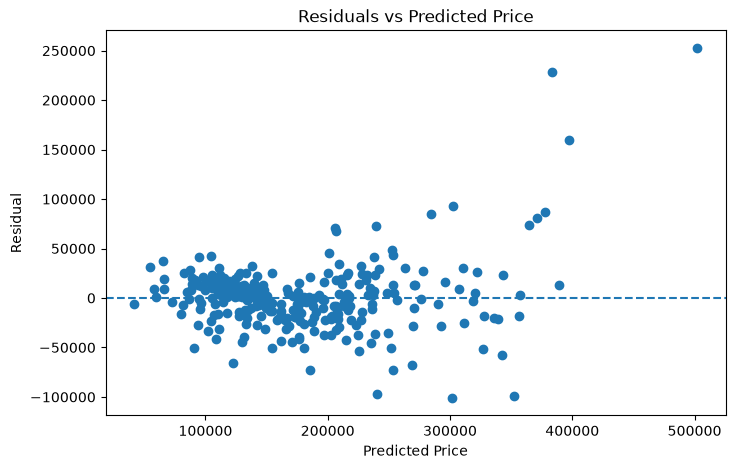

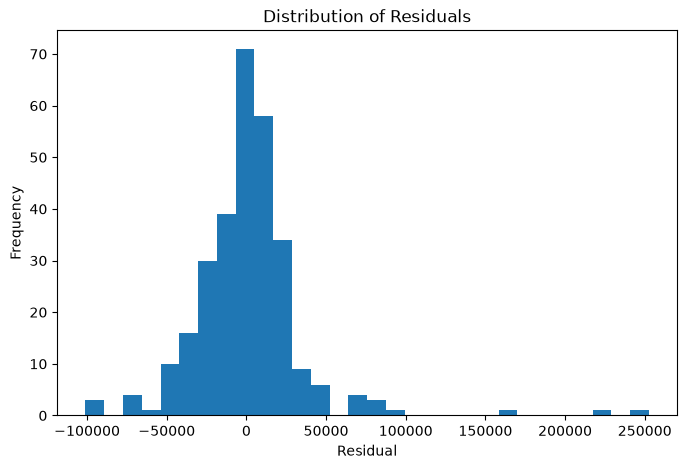

In [9]:
residuals = y_valid - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Price")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

**Interpretation:** Ideally residuals should be spread around zero without any pattern. A curve or funnel shape would show that the linear model is missing some relationship, in the data.

### Task 12

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_valid, y_pred)
mse = mean_squared_error(y_valid, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_valid, y_pred)

test_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Value": [mae, mse, rmse, r2]
})

print(test_metrics)

  Metric         Value
0    MAE  2.155977e+04
1    MSE  1.225906e+09
2   RMSE  3.501294e+04
3     R²  8.401755e-01


**Interpretation:** MAE stands for absolute error and it tells us the average size of the prediction errors in the same units as the prices. This means it gives an idea of how far off the predictions are, on average. MSE or mean squared error squares the errors before averaging them. Because of this large errors get more attention in MSE. RMSE or root mean squared error takes the root of MSE so it ends up in the same units as the prices. Like MSE, RMSE is also sensitive to errors but it’s easier to understand since it’s in price units. R-squared or R² shows how much of the variation, in prices the model can explain. A higher R² means the model fits the data better.

### Task 13

MAE is easiest for a non-technical stakeholder because it represents the average prediction error in the same units as house price. MSE penalizes large errors more strongly, RMSE gives a price-unit error with that same sensitivity, and R² describes how much variation is explained by the model.

## Part 6, Training vs Testing & Generalization

### Task 14

In [11]:
train_pred = model.predict(X_train)

train_mae = mean_absolute_error(y_train, train_pred)
train_mse = mean_squared_error(y_train, train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, train_pred)

performance = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Training": [train_mae, train_mse, train_rmse, train_r2],
    "Testing": [mae, mse, rmse, r2]
})

print(performance)

  Metric      Training       Testing
0    MAE  2.046454e+04  2.155977e+04
1    MSE  1.040429e+09  1.225906e+09
2   RMSE  3.225568e+04  3.501294e+04
3     R²  8.255646e-01  8.401755e-01


**Interpretation:** The table clearly shows how the model performs during training and, during testing so it is easy to see how well the model can be used in situations. The models ability to work well with data is what is being checked. The models ability to work well with data is important to understand.

### Task 15

In [12]:
print("MAE gap:", abs(train_mae - mae))
print("MSE gap:", abs(train_mse - mse))
print("RMSE gap:", abs(train_rmse - rmse))
print("R² gap:", abs(train_r2 - r2))

MAE gap: 1095.2285473843986
MSE gap: 185477166.15386927
RMSE gap: 2757.261377780269
R² gap: 0.014610923601815928


**Interpretation:** A big gap, between training and testing performance might suggest overfitting.. We should not jump to that conclusion right away. Instead we need to look at the numbers that are shown. Those values tell us what is really happening. The difference printed above is what we should base our judgment on. So always check the gap before saying overfitting is the cause.

## Part 7, Final Model Analysis, Conclusion & Kaggle Submission

### Task 16

In [13]:
coefficient_table["Absolute Coefficient"] = coefficient_table["Coefficient"].abs()

top_coefficients = coefficient_table.sort_values(
    "Absolute Coefficient",
    ascending=False
).head(5)

print(top_coefficients[["Feature", "Coefficient"]])

                 Feature   Coefficient
21  Neighborhood_NoRidge  51901.677977
28  Neighborhood_StoneBr  38581.520151
39        KitchenQual_Ex  38408.270810
22  Neighborhood_NridgHt  32860.731256
43     GarageType_2Types -31649.258904


**Interpretation:** These features have the coefficient values in the model.. Just looking at the size of the coefficients doesn't tell the full story. That's because the features are measured in units and, on different scales. So even if a coefficient is large it doesn't always mean the feature is more important. We need to think about scaling and units when judging importance.

### Task 17

Linear Regression gives an easy way to guess house prices from the chosen features. MAE, RMSE and R² help us see how well Linear Regression works, better, than classification accuracy. The coefficient table shows which features push house prices up and which pull them down. Residual plots let us know if important patterns are still hidden. One problem is that house prices may follow patterns that Linear Regression cannot catch. Another problem is that only a small set of features was used. A good next step is to do feature engineering and to test nonlinear regression models.

### Task 18

In [14]:
# Train on all labeled houses before making Kaggle predictions.
final_model = LinearRegression()
final_model.fit(X, y)

kaggle_predictions = final_model.predict(X_test_kaggle)

submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": kaggle_predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print("\nSubmission shape:", submission.shape)
print("\nColumns:", submission.columns.tolist())

     Id      SalePrice
0  1461  113110.262286
1  1462  160446.741557
2  1463  164275.109875
3  1464  181926.646325
4  1465  253799.796817

Submission shape: (1459, 2)

Columns: ['Id', 'SalePrice']


**Interpretation:** I noticed that the submission contains Id and SalePrice, which matches the required format. I also see that the row count of the submission should match the row count of test.csv.

### Task 19

Upload `submission.csv` to Kaggle using the competition's **Submit Predictions** page.

**Public Leaderboard Score:** 0.17198

**Public Leaderboard Rank:** 2833

**Experience:** I successfully submitted my submission.csv file to Kaggle.

The public leaderboard score was 0.17198.

This score showed that the Linear Regression model could predict house prices, on the Kaggle test data and the Linear Regression model performed well with house prices.

## Conclusion

In this lab we used Multiple Linear Regression, on the House Prices dataset to predict SalePrice.

The process involved selecting features handling missing values converting variables with one‑hot encoding splitting the data into training and testing sets training the model making predictions, interpreting coefficients analyzing residuals and computing regression metrics.

MAE, MSE, RMSE and R² were calculated to view the model from angles.

The coefficient table helped make the model easier to interpret and residual plots revealed patterns that a simple linear model could miss.

Linear Regression is valuable because it is straightforward and easy to understand yet house prices often show patterns that call for more powerful models.

Future work could include feature engineering and the use of nonlinear models.

## Submission Checklist

- [x] Student-info block
- [x] Dataset exploration
- [x] Problem definition
- [x] Feature and target identification
- [x] Data preparation
- [x] Train/test split
- [x] Linear Regression model
- [x] Predictions
- [x] Coefficients and intercept
- [x] Residual analysis
- [x] MAE, MSE, RMSE and R²
- [x] Training vs testing comparison
- [x] Model interpretation
- [x] Conclusion
- [x] Kaggle submission code